In [ ]:
##################################################################################
# # ! Magnetic field on a plane above a dipole — 2×2 summary figure
##################################################################################
# %%
# # ! Setup
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 300
from magnetic_forward_numba import *

In [ ]:
# # ! Computation grid
mu0 = 4 * np.pi * 1e-7   # Permeability of free space in H/m
M = 100.                 # Dipole moment magnitude in A·m²
pos_M = np.array([0., 0., 10.])

nor_1, nor_2, Nnor = -30., 30., 121
est_1, est_2, Nest = -30., 30., 121
NorF = np.linspace(nor_1, nor_2, Nnor)
EstF = np.linspace(est_1, est_2, Nest)
NORF, ESTF = np.meshgrid(NorF, EstF)
DWDF = 0.0 * np.ones(NORF.shape)
obs_nor_f = NORF.ravel()
obs_est_f = ESTF.ravel()
obs_dwd_f = DWDF.ravel()
obs_ned_f = np.column_stack((obs_nor_f, obs_est_f, obs_dwd_f))

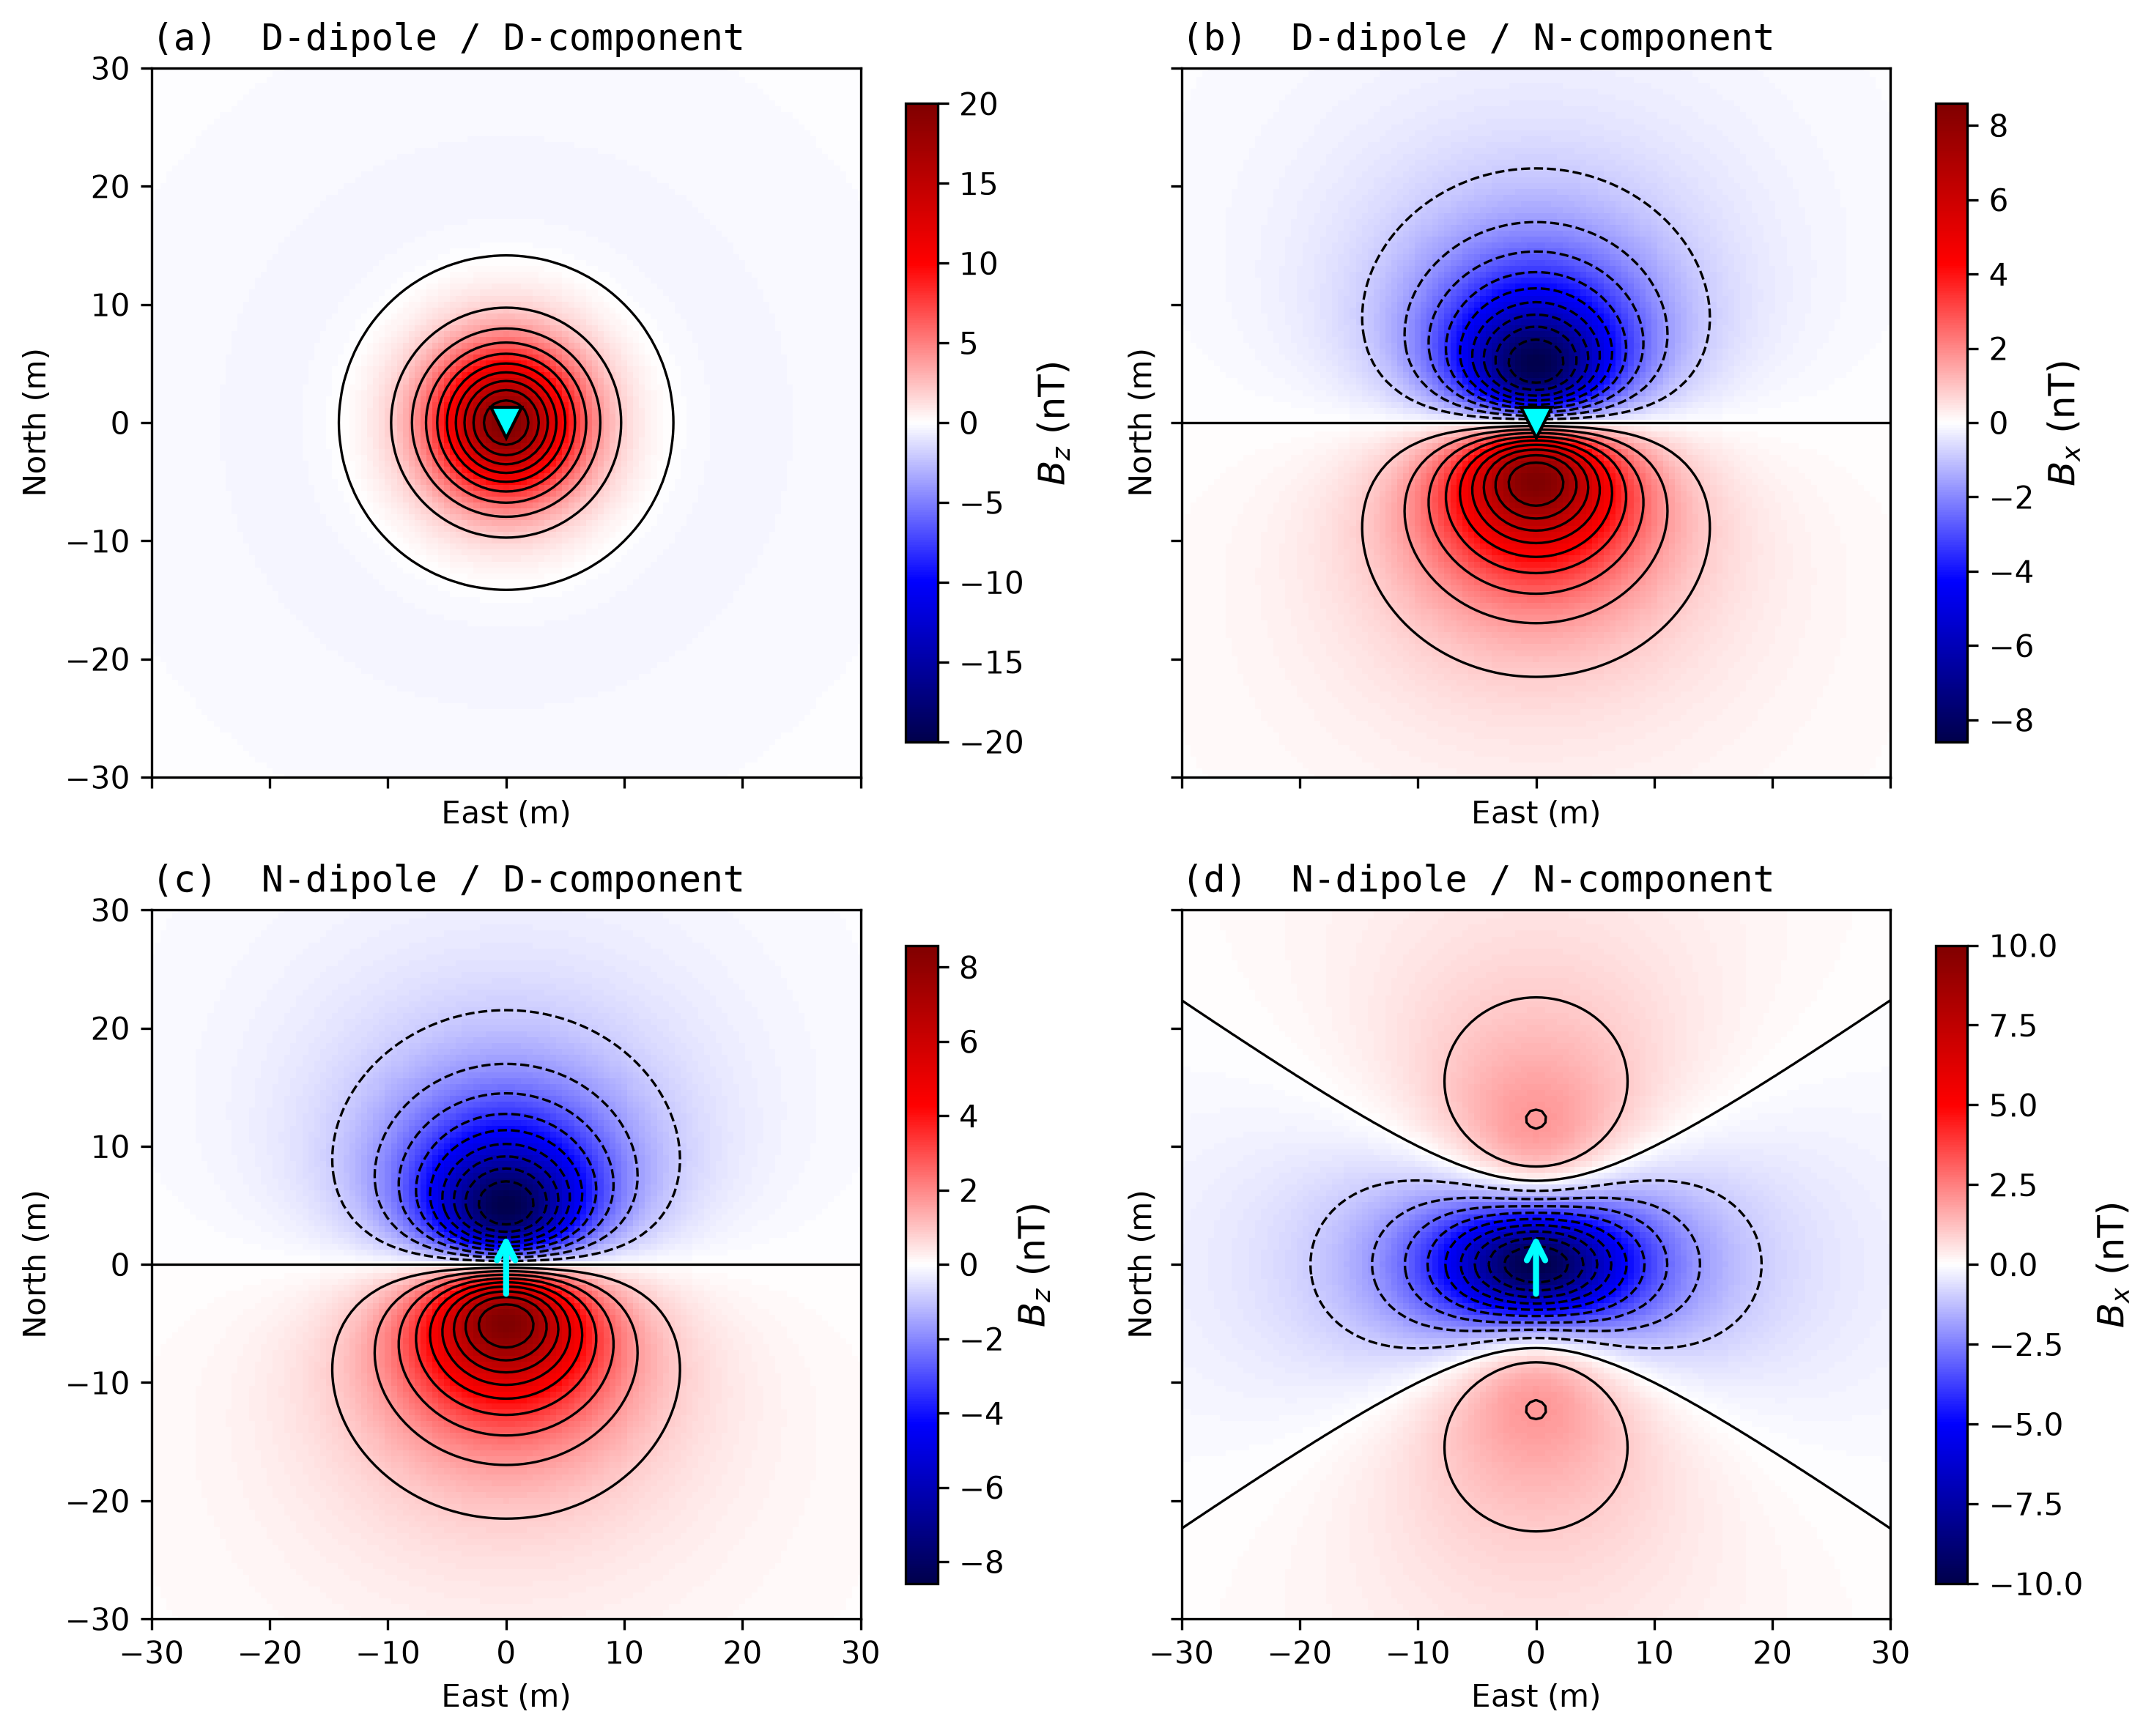

In [ ]:
# # ! Case definitions
cases = [
    ('D', 'D'),   # (a) Downward dipole, Downward component
    ('D', 'N'),   # (b) Downward dipole, Northward component
    ('N', 'D'),   # (c) Northward dipole, Downward component
    ('N', 'N'),   # (d) Northward dipole, Northward component
]
labels = ['(a)', '(b)', '(c)', '(d)']

fig, axes = plt.subplots(2, 2, figsize=(10, 8), 
                         sharex=True, sharey=True)
axes = axes.ravel()

for idx, (dip_orient, comp) in enumerate(cases):
    ax = axes[idx]

    # Dipole moment vector
    if dip_orient.upper() == 'D':
        mx, my, mz = 0., 0., M
    elif dip_orient.upper() == 'N':
        mx, my, mz = M, 0., 0.
    dip_M = np.array([mx, my, mz])

    # Compute field
    obs_bn_f, obs_be_f, obs_bd_f = dipole_field(obs_ned_f, dip_M, pos_M)

    # Select scalar component
    if comp.upper() == 'D':
        comp_name = 'bd'
        comp_label = r'$B_z$ (nT)'
        obs_bc_f = obs_bd_f
    else:
        comp_name = 'bn'
        comp_label = r'$B_x$ (nT)'
        obs_bc_f = obs_bn_f

    Bc = obs_bc_f.reshape((Nest, Nnor))
    bc_max = np.abs(obs_bc_f).max()

    # Colormesh
    pcm = ax.pcolormesh(
        ESTF, NORF, Bc,
        cmap='seismic',
        vmin=-bc_max, vmax=bc_max,
        shading='auto'
    )

    # Contours
    ax.contour(
        ESTF, NORF, Bc,
        levels=np.linspace(-bc_max, bc_max, 21),
        colors='black', linewidths=0.8
    )

    # Dipole projection marker at origin
    dir_M = dip_M / np.linalg.norm(dip_M)
    arrow_scale = 6.0
    # Only plot horizontal projection; for vertical dipole show a small dot
    if dip_orient.upper() == 'D':
        ax.plot(pos_M[1], pos_M[0], marker='v', color='cyan', markersize=10,
                markeredgecolor='black', zorder=5)
    else:
        ax.annotate(
            '', 
            xy=(pos_M[1] + arrow_scale/2 * dir_M[1], 
                pos_M[0] + arrow_scale/2 * dir_M[0]),
            xytext=(pos_M[1] - arrow_scale/2 * dir_M[1], 
                    pos_M[0] - arrow_scale/2 * dir_M[0]),
            arrowprops=dict(arrowstyle='->', color='cyan', lw=2,
                            mutation_scale=15),
            zorder=6)

    # Labeling
    ax.set_title(f"{labels[idx]}  {dip_orient.upper()}-dipole / {comp.upper()}-component",
                 fontsize=12, loc='left', fontfamily='monospace')
    ax.set_xlabel('East (m)')
    ax.set_ylabel('North (m)')
    ax.set_aspect('equal')
    ax.set_xlim(est_1, est_2)
    ax.set_ylim(nor_1, nor_2)

    # Colorbar per subplot
    cbar = fig.colorbar(pcm, ax=ax, orientation='vertical',
                        shrink=0.9, pad=0.05)
    cbar.set_label(comp_label, fontsize=12)
    cbar.ax.tick_params(labelsize=10)

plt.tight_layout()
plt.show()